Top 10 Neighborhoods by Playground Count:


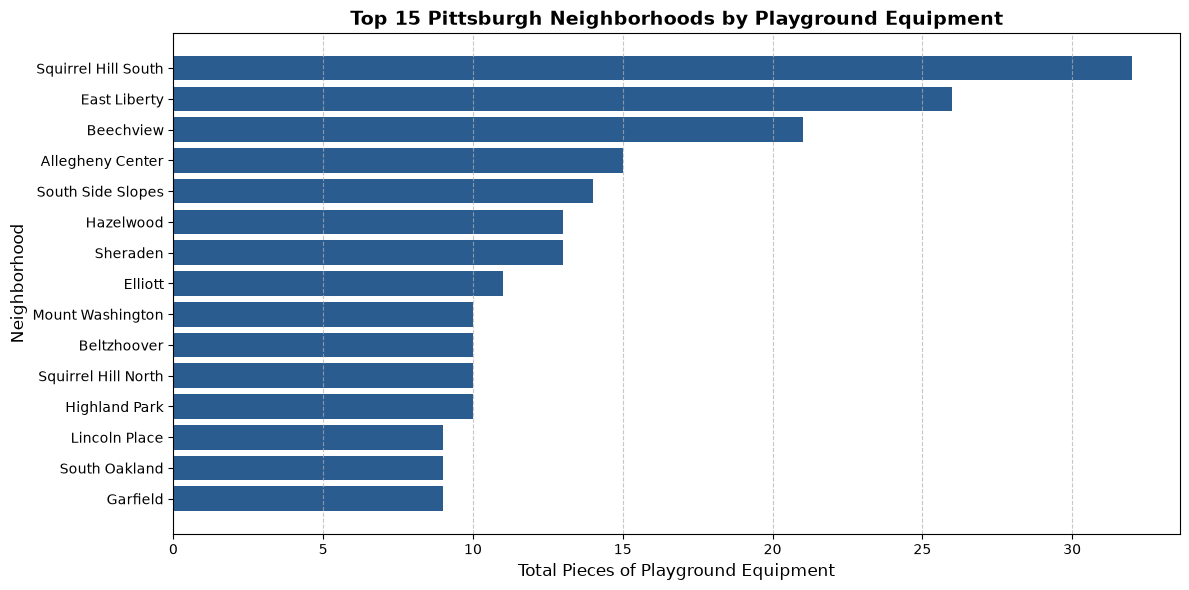

Saved playground submetric dataset to 'playground_submetric.csv'


In [6]:
import matplotlib.pyplot as plt
import pandas as pd

url = "https://data.wprdc.org/datastore/dump/e39ef76e-0a11-47c8-a86f-a37f55db7a2b"
playgrounds = pd.read_csv(url)

playgrounds.columns = playgrounds.columns.str.lower()
playgrounds = playgrounds.dropna(subset=["neighborhood"])

neighborhood_playgrounds = (
    playgrounds_clean.groupby("neighborhood")
    .agg(
        total_equipment=("id", "count"),
        unique_playgrounds=("name", "nunique"),
        equipment_diversity=("equipment_type", "nunique"),
    )
    .reset_index()
)

neighborhood_playgrounds = neighborhood_playgrounds.sort_values(
    by="total_equipment", ascending=False
).reset_index(drop=True)

max_equipment = neighborhood_playgrounds["total_equipment"].max()
neighborhood_playgrounds["playground_score"] = (
    neighborhood_playgrounds["total_equipment"] / max_equipment
) * 100

print("Top 10 Neighborhoods by Playground Count:")
neighborhood_playgrounds.head(10)

plt.figure(figsize=(12, 6))
top_15 = neighborhood_playgrounds.head(15)

plt.barh(top_15["neighborhood"], top_15["total_equipment"], color="#2b5c8f")
plt.xlabel("Total Pieces of Playground Equipment", fontsize=12)
plt.ylabel("Neighborhood", fontsize=12)
plt.title("Top 15 Pittsburgh Neighborhoods by Playground Equipment", fontsize=14, fontweight="bold")
plt.gca().invert_yaxis()  
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

neighborhood_playgrounds.to_csv("playground_submetric.csv", index=False)
print("Saved playground submetric dataset to 'playground_submetric.csv'")